# 03 — Candidate-pool scaling microbenchmark (PyTorch)

**Purpose:** isolate the computational behavior of two MMR implementations as the candidate count grows:

- **Incremental MMR:** update each candidate's maximum redundancy after selecting a document, with approximately \(O(kNd)\) similarity work.
- **Full pairwise-matrix MMR:** materialize the \(N\times N\) document-similarity matrix first, which costs approximately \(O(N^2d)\) compute and \(O(N^2)\) memory.

This notebook uses deterministic synthetic embeddings. It is a **pure algorithmic stress test**, not a retrieval-effectiveness experiment and not evidence that a method improves search quality. It is useful to locate break-even points and validate the implementation before measuring real candidate pools.

# 0. Initial Setup

In [9]:
! uv pip install seaborn
import seaborn as sns

Using Python 3.13.3 environment at: D:\01 Work\13-research-MaxMarginalRelevance\.venv
Audited 1 package in 260ms


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [11]:
import math
import time
import platform

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

In [13]:
sns.set_theme(
    style="darkgrid",
    context="talk",
    font_scale=0.82
)

In [ ]:
SEED = 42
DEVICE = "cuda" 
EMBEDDING_DIM = 384
TOP_K = 10
LAMBDA_MULT = 0.65
CANDIDATE_COUNTS = [10, 25, 50, 100, 250, 500]
WARMUP_REPEATS = 3
TIMING_REPEATS = 20

In [3]:
def select_mmr_incremental(
    query_embedding: torch.Tensor,
    document_embeddings: torch.Tensor,
    lambda_mult: float = 0.65,
    top_k: int = 10,
    redundancy_floor: float = 0.0,
) -> list[int]:
    """Select top-k documents using incremental redundancy updates."""
    if not 0 <= lambda_mult <= 1:
        raise ValueError("lambda_mult must be between 0 and 1")
    relevance = document_embeddings @ query_embedding
    n_docs = document_embeddings.shape[0]
    available = torch.ones(n_docs, dtype=torch.bool, device=document_embeddings.device)
    max_redundancy = torch.zeros(n_docs, dtype=document_embeddings.dtype,
                                  device=document_embeddings.device)
    selected = []
    for _ in range(min(top_k, n_docs)):
        scores = lambda_mult * relevance - (1.0 - lambda_mult) * max_redundancy
        scores = scores.masked_fill(~available, -torch.inf)
        chosen = int(torch.argmax(scores).item())
        selected.append(chosen)
        available[chosen] = False
        similarity = document_embeddings @ document_embeddings[chosen]
        max_redundancy = torch.maximum(
            max_redundancy, torch.clamp(similarity, min=redundancy_floor)
        )
    return selected


def select_mmr_pairwise_matrix(
    query_embedding: torch.Tensor,
    document_embeddings: torch.Tensor,
    lambda_mult: float = 0.65,
    top_k: int = 10,
    redundancy_floor: float = 0.0,
) -> list[int]:
    """Reference implementation that precomputes all N-by-N cosine similarities."""
    relevance = document_embeddings @ query_embedding
    pairwise = document_embeddings @ document_embeddings.T
    if redundancy_floor is not None:
        pairwise = torch.clamp(pairwise, min=redundancy_floor)
    n_docs = document_embeddings.shape[0]
    available = torch.ones(n_docs, dtype=torch.bool, device=document_embeddings.device)
    max_redundancy = torch.zeros(n_docs, dtype=document_embeddings.dtype,
                                  device=document_embeddings.device)
    selected = []
    for _ in range(min(top_k, n_docs)):
        scores = lambda_mult * relevance - (1.0 - lambda_mult) * max_redundancy
        scores = scores.masked_fill(~available, -torch.inf)
        chosen = int(torch.argmax(scores).item())
        selected.append(chosen)
        available[chosen] = False
        max_redundancy = torch.maximum(max_redundancy, pairwise[:, chosen])
    return selected


def synchronize_if_needed(device: torch.device) -> None:
    """Wait for asynchronous CUDA kernels before recording wall-clock latency."""
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def measure_latency_ms(function, device: torch.device, warmups: int, repeats: int) -> np.ndarray:
    """Return individual wall-clock durations in milliseconds."""
    for _ in range(warmups):
        function()
    synchronize_if_needed(device)
    values = []
    for _ in range(repeats):
        synchronize_if_needed(device)
        start = time.perf_counter_ns()
        function()
        synchronize_if_needed(device)
        values.append((time.perf_counter_ns() - start) / 1_000_000.0)
    return np.asarray(values, dtype=np.float64)


def make_embeddings(n_docs: int, dim: int, device: str, seed: int):
    """Generate reproducible normalized embeddings for algorithm-only testing."""
    generator = torch.Generator(device="cpu").manual_seed(seed + n_docs)
    query = F.normalize(torch.randn(dim, generator=generator), dim=0)
    docs = F.normalize(torch.randn(n_docs, dim, generator=generator), dim=1)
    return query.to(device), docs.to(device)


def summarize_timing(values: np.ndarray) -> dict[str, float]:
    """Summarize latency observations without discarding the raw samples."""
    return {
        "mean_ms": float(np.mean(values)),
        "p50_ms": float(np.percentile(values, 50)),
        "p95_ms": float(np.percentile(values, 95)),
        "p99_ms": float(np.percentile(values, 99)),
        "min_ms": float(np.min(values)),
        "max_ms": float(np.max(values)),
    }


torch.manual_seed(SEED)
torch.set_num_threads(1)
if DEVICE.startswith("cuda") and not torch.cuda.is_available():
    raise RuntimeError("CUDA requested but unavailable; set DEVICE='cpu'.")
print({
    "python": platform.python_version(),
    "torch": torch.__version__,
    "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE.startswith("cuda") else None,
})

{'python': '3.13.3', 'torch': '2.11.0+cu128', 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 3050 Laptop GPU'}


# 1. Verify that the two implementations produce identical rankings

The pairwise-matrix implementation is used as an equivalence reference. If rankings differ, do not trust the timing comparison; inspect tie-breaking, the redundancy floor, and candidate ordering first.

In [4]:
query_check, docs_check = make_embeddings(100, EMBEDDING_DIM, DEVICE, SEED)
order_incremental = select_mmr_incremental(query_check, docs_check, LAMBDA_MULT, TOP_K)
order_pairwise = select_mmr_pairwise_matrix(query_check, docs_check, LAMBDA_MULT, TOP_K)
assert order_incremental == order_pairwise, (
    "The implementations differ; debug correctness before benchmarking."
)
print("PASS: incremental and pairwise-matrix implementations return the same top-k order.")

PASS: incremental and pairwise-matrix implementations return the same top-k order.


# 2. Measure candidate-count scaling

Use the same query/document vectors for both methods at each candidate count. Synchronize CUDA during timing, include Python selection overhead, and report p50/p95 rather than only the fastest run. The first run may include runtime/allocator effects; warmups are discarded.

In [5]:
rows = []
raw_latency = {}
for n_docs in CANDIDATE_COUNTS:
    query_vector, document_vectors = make_embeddings(
        n_docs, EMBEDDING_DIM, DEVICE, SEED
    )
    incremental = lambda: select_mmr_incremental(
        query_vector, document_vectors, LAMBDA_MULT, TOP_K
    )
    pairwise = lambda: select_mmr_pairwise_matrix(
        query_vector, document_vectors, LAMBDA_MULT, TOP_K
    )

    # Correctness check at every N, not only the small example.
    assert incremental() == pairwise(), f"Ranking mismatch at N={n_docs}"

    for name, function in [
        ("incremental", incremental),
        ("full_pairwise_matrix", pairwise),
    ]:
        latencies = measure_latency_ms(
            function, torch.device(DEVICE), WARMUP_REPEATS, TIMING_REPEATS
        )
        raw_latency[(n_docs, name)] = latencies
        rows.append({
            "candidate_count": n_docs,
            "method": name,
            "embedding_dim": EMBEDDING_DIM,
            "top_k": min(TOP_K, n_docs),
            **summarize_timing(latencies),
        })

scaling_results = pd.DataFrame(rows).sort_values(["candidate_count", "method"])
display(scaling_results.round(4))

,candidate_count,method,embedding_dim,top_k,mean_ms,p50_ms,p95_ms,p99_ms,min_ms,max_ms
1,10,full_pairwise_matrix,384,10,3.5421,3.4642,4.7652,5.2679,2.4532,5.3936
0,10,incremental,384,10,4.7441,3.9090,9.2849,10.0427,2.9291,10.2321
3,25,full_pairwise_matrix,384,10,3.2204,2.9125,4.4589,5.6477,2.4306,5.9449
2,25,incremental,384,10,3.7206,3.3926,5.0866,5.4114,2.9822,5.4926
5,50,full_pairwise_matrix,384,10,3.1036,2.7106,3.9555,6.8850,2.4170,7.6174
4,50,incremental,384,10,3.6499,3.2244,4.5598,6.4943,2.8667,6.9779
7,100,full_pairwise_matrix,384,10,3.4241,3.0926,4.4856,4.6098,2.6240,4.6409
6,100,incremental,384,10,3.7648,3.3439,5.0585,5.4859,2.9036,5.5927
9,250,full_pairwise_matrix,384,10,3.5225,3.1446,4.7667,5.5571,2.6898,5.7547
8,250,incremental,384,10,3.7876,3.4253,5.1322,5.5676,3.1316,5.6764


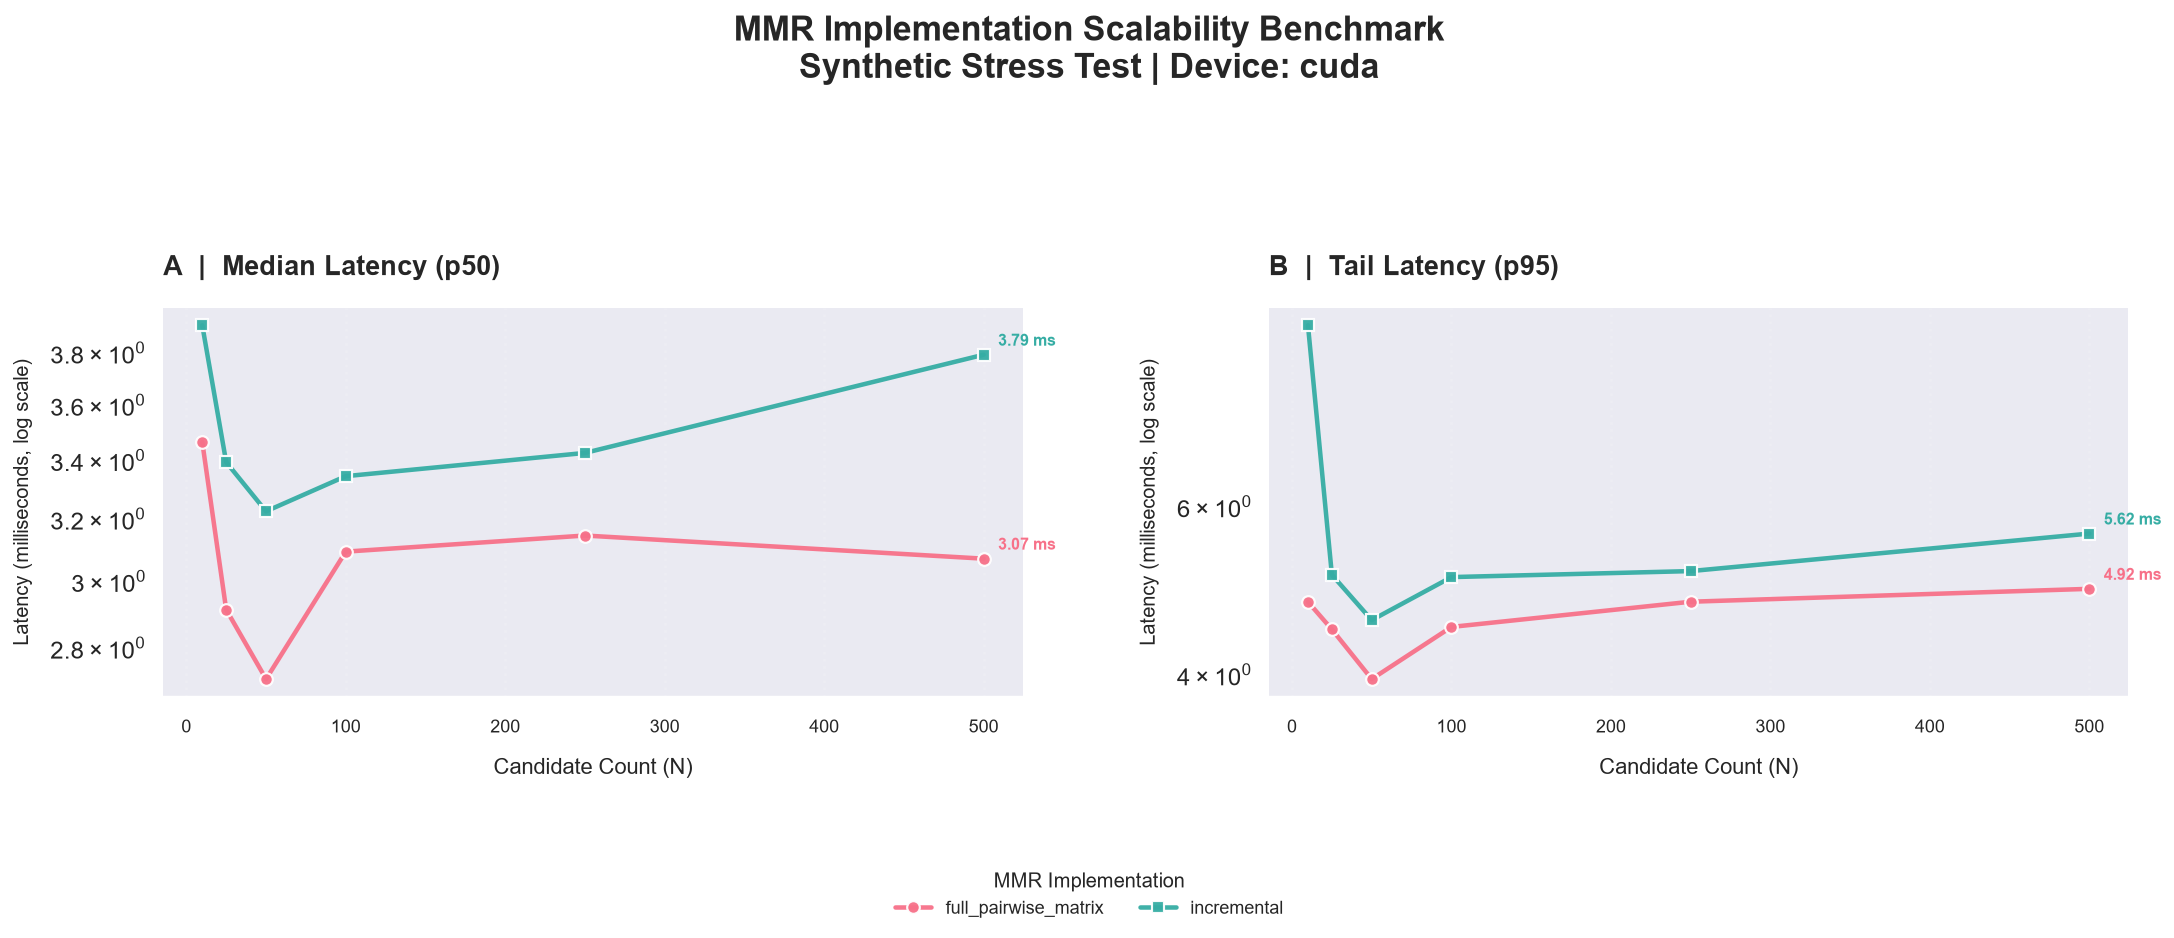

In [14]:
plot_df = scaling_results.copy()

# Ensure correct ordering
plot_df = plot_df.sort_values(
    ["method", "candidate_count"]
)

methods = sorted(plot_df["method"].unique())

# Consistent colors across both panels
palette = sns.color_palette(
    "husl",
    n_colors=len(methods)
)

method_colors = dict(zip(methods, palette))

markers = ["o", "s", "D", "^", "v", "P", "X", "*"]

# ============================================================
# 3. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 6.5),
    dpi=130,
    sharex=True,
    gridspec_kw={"width_ratios": [1, 1]}
)

fig.suptitle(
    f"MMR Implementation Scalability Benchmark\n"
    f"Synthetic Stress Test | Device: {DEVICE}",
    fontsize=19,
    fontweight="bold",
    y=1.06
)

# ============================================================
# 4. PLOT LATENCY CURVES
# ============================================================

metrics = [
    ("p50_ms", "A  |  Median Latency (p50)"),
    ("p95_ms", "B  |  Tail Latency (p95)")
]

for ax, (metric, title) in zip(axes, metrics):

    for i, method in enumerate(methods):

        group = plot_df[
            plot_df["method"] == method
        ].sort_values("candidate_count")

        # Log scale requires positive values
        group = group[
            (group["candidate_count"] > 0)
            & (group[metric] > 0)
        ]

        if group.empty:
            continue

        ax.plot(
            group["candidate_count"],
            group[metric],
            label=method,
            color=method_colors[method],
            marker=markers[i % len(markers)],
            markersize=7,
            linewidth=2.5,
            markeredgecolor="white",
            markeredgewidth=1.2,
            alpha=0.95
        )

        # Annotate final latency
        last = group.iloc[-1]

        ax.annotate(
            f'{last[metric]:.2f} ms',
            xy=(
                last["candidate_count"],
                last[metric]
            ),
            xytext=(8, 5),
            textcoords="offset points",
            fontsize=9,
            color=method_colors[method],
            fontweight="bold"
        )

    # ========================================================
    # 5. AXIS STYLING
    # ========================================================

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        loc="left",
        pad=18
    )

    ax.set_xlabel(
        "Candidate Count (N)",
        fontsize=12,
        labelpad=12
    )

    ax.set_ylabel(
        "Latency (milliseconds, log scale)",
        fontsize=11,
        labelpad=10
    )

    ax.set_yscale("log")

    ax.yaxis.set_major_locator(
        LogLocator(base=10, numticks=8)
    )

    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda y, _: f"{y:g}")
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.15
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.set_axisbelow(True)

    sns.despine(
        ax=ax,
        top=True,
        right=True,
        left=True
    )

# ============================================================
# 6. SHARED LEGEND
# ============================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="MMR Implementation",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.03),
    ncol=min(len(methods), 4),
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

# ============================================================
# 7. FINAL LAYOUT
# ============================================================

plt.tight_layout(
    rect=[0, 0.12, 1, 0.93],
    w_pad=3
)

plt.show()

In [7]:
scaling_results.to_csv("mmr_scaling_stress_test.csv", index=False)
print("Saved mmr_scaling_stress_test.csv in the current working directory.")

Saved mmr_scaling_stress_test.csv in the current working directory.


# 3. Interpret the benchmark

- These are timings of synthetic embedding tensors and two implementations, not retrieval effectiveness on a public search corpus.
- The full-matrix method is a comparison point, not necessarily the best optimized implementation of every diversification algorithm.
- Incremental MMR still performs roughly \(kNd\) similarity work. Real end-to-end latency also includes retrieval, text embedding if not cached, feature extraction, serialization, queuing, and network/service overhead.
- Repeat on your target machine and on a realistic candidate pool; report hardware and thread count. Do not combine local CPU timings with Colab GPU timings in one latency ranking without a carefully controlled protocol.